# Running this notebook in lumina-sdk

Use a Python 3.10+ Jupyter kernel with the dependencies installed. From the
`lumina-sdk` repository root, install them into the kernel's environment:

```bash
python -m pip install -r distillation/conversion/requirements.txt
```

The local converter is in `../conversion/convert.py`; the first code cell locates
it from the notebook directory or anywhere inside this checkout.

The data path is selected from the hostname (case-insensitive):

- **Aurora** (`aurora-*` or `x*`):
  `/lus/flare/projects/FRAME-IDP/siebenschuh/acopf_datasets/raw/OPFData`.
  The loader reuses archives directly in `dataset_release_1/` and downloads
  missing archives there. PyG's processed splits are stored under
  `dataset_release_1/<case>/processed_<num_groups>/`.
- **MacBook** (hostname contains `MacBook`): `~/data/datasets/OPFData`,
  using the original PyTorch Geometric dataset layout.
- Other hosts raise `RuntimeError` before loading or downloading data.

On Aurora, archives are extracted when processed splits are missing; later
runs reuse those splits. The path is set by the hostname cell below.

Defaults match the original: case118, five groups, training sample 10000.
`OPF_NUM_GROUPS` and `OPF_SAMPLE_INDEX` can override these two numeric settings.
Select your Python environment's kernel and run the cells in order.


In [6]:
from pathlib import Path
import os
import sys

# Locate the checkout from either the notebook directory or the repository root.
working_dir = Path.cwd().resolve()
for candidate in (working_dir, *working_dir.parents):
    if (candidate / "distillation" / "conversion" / "convert.py").is_file():
        repo_root = candidate
        break
else:
    raise FileNotFoundError("Launch this notebook from within the lumina-sdk checkout.")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import torch
from torch_geometric.datasets import OPFDataset
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import inspect

from opf_data import get_data_path, load_dataset
from visualize_network import plot_network

from pypower.api import runopf, ppoption
from distillation.conversion import hetero_to_ppc


# AC-OPF: AC Optimal Power Flow 

We largely follow the formalism of [LUMINA](https://arxiv.org/pdf/2605.02133v1) of Jin et al. (2026). The AC optimal power flow problem (AC-OPF for short) aims to minimize the total generation cost $C(\mathbf{P})$ while satisfying physical constraints and load demand at all times. 

### Data format
Data is stored as [`HeteroData`](https://pytorch-geometric.readthedocs.io/en/2.5.0/generated/torch_geometric.data.HeteroData.html), an object from `torch_geometric` that describes a heterogeneous graph, holding multiple node and/or edge types. It stores the multiple `x` matrices for nodes (bus, generator, load, shunts) and edges (9 for line edge, 11 for transformer, none for link edge). Nodes are accessed by key, e.g. `data['bus']`, ..., `data['generator']` while 

In [7]:
# load data
opf_path, use_shared_archives = get_data_path()
print(opf_path)

ds = load_dataset()
data = ds[5000]

/lus/flare/projects/FRAME-IDP/siebenschuh/acopf_datasets/raw/OPFData


In [16]:
for i in [1,50,250,500,1000, 1500, 2000, 3000, 5000]:
    print(f"# data{i}")
    print(ds[i])

# data1
HeteroData(
  x=[1],
  objective=[1],
  bus={
    x=[118, 4],
    y=[118, 2],
  },
  generator={
    x=[54, 11],
    y=[54, 2],
  },
  load={ x=[99, 2] },
  shunt={ x=[14, 2] },
  (bus, ac_line, bus)={
    edge_index=[2, 175],
    edge_attr=[175, 9],
    edge_label=[175, 4],
  },
  (bus, transformer, bus)={
    edge_index=[2, 11],
    edge_attr=[11, 11],
    edge_label=[11, 4],
  },
  (generator, generator_link, bus)={ edge_index=[2, 54] },
  (bus, generator_link, generator)={ edge_index=[2, 54] },
  (load, load_link, bus)={ edge_index=[2, 99] },
  (bus, load_link, load)={ edge_index=[2, 99] },
  (shunt, shunt_link, bus)={ edge_index=[2, 14] },
  (bus, shunt_link, shunt)={ edge_index=[2, 14] }
)
# data50
HeteroData(
  x=[1],
  objective=[1],
  bus={
    x=[118, 4],
    y=[118, 2],
  },
  generator={
    x=[54, 11],
    y=[54, 2],
  },
  load={ x=[99, 2] },
  shunt={ x=[14, 2] },
  (bus, ac_line, bus)={
    edge_index=[2, 175],
    edge_attr=[175, 9],
    edge_label=[175, 4],
  

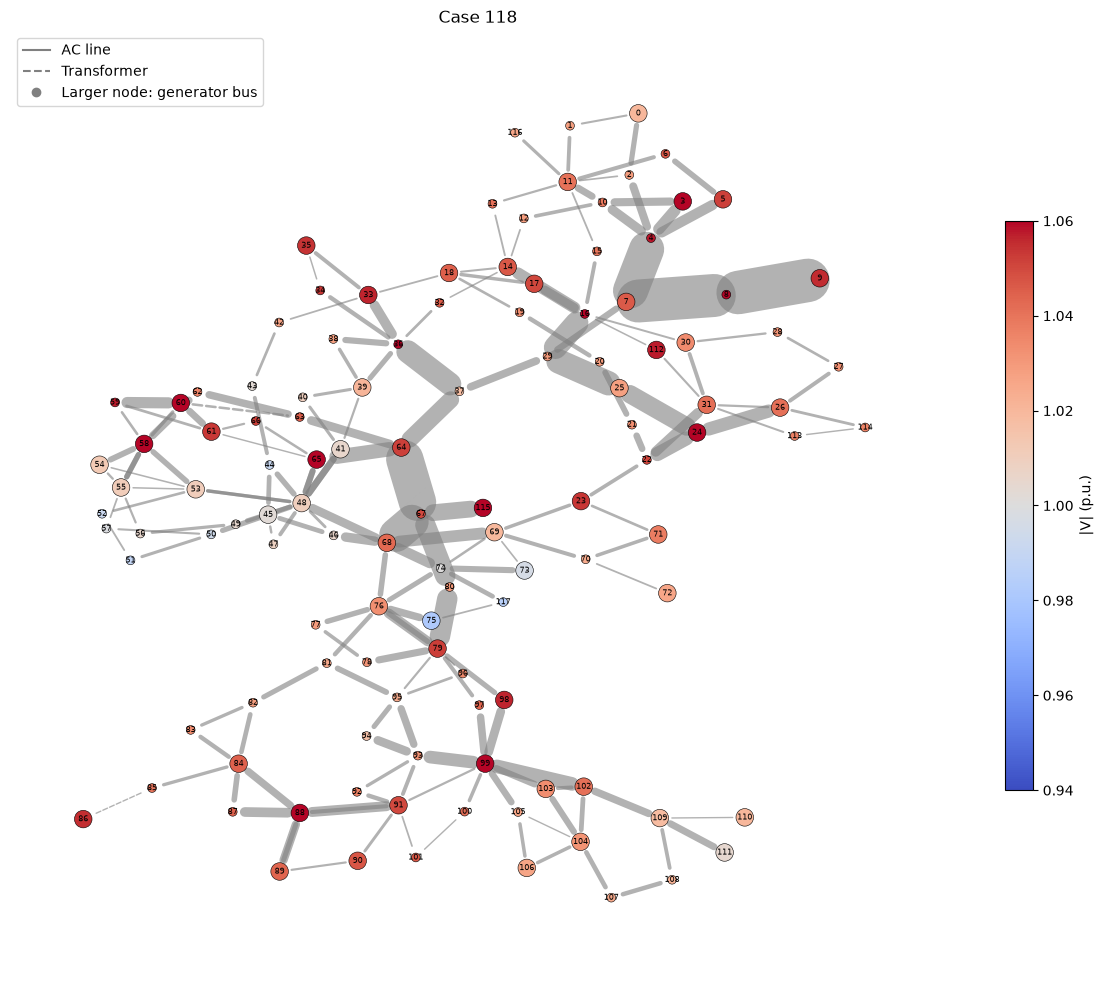

(<Figure size 1200x1000 with 2 Axes>, <Axes: title={'center': 'Case 118'}>)

In [11]:
# plot_network(data, mode="topology")
plot_network(data, mode="combined", title="Case 118")

# 1. Network structure

The data is sourced from Deepmind's [OPFData](https://arxiv.org/abs/2406.07234v1). 

## Buses $\mathcal{N}$
The node set $\mathcal{N} = { 1,...,N }$ of buses is represented by `data['bus']`. 
The bus feature matrix `data['bus'].x` (shape `[N,4]`) are the inputs: base_kv, bus_type, vmin, vmax. 

The bus state (target) `data['bus'].y` of shape `[N,2]` are the complex voltage states `va` (voltage angle $\theta_{i}$) and `vm` (voltage magnitude $v_{i}$) for $V_{i} = v_{i} e^{\mathrm{j} \theta_{i}}$.

## Units
**baseMVA** (*Bezugsleistung*)
Single scalar value in `data.x` that defined the graph-level scalar baseMVA.Every other quantity becomes per unit `p.u.` 
Stored as length-1 tensor so it is compatible with batching. 

$P$: active power (*Wirkleistung*) [**MW**], the part that does "work" (as Watt = one Joule of energy per unit of time)

$Q$: reactive power(*Blindleistung*) [**MVAr**]

$S=P + \mathrm{j} Q$: apparent power with $|S|=\sqrt{P^{2} + Q^{2}}$ [**MVA**], the total the wires and machines actually have to carry.

$\mathrm{arctan}(\varphi) = Q / P$ is the phase shift between voltage and current

$\mathrm{cos}(\varphi) = P / |S|$ is the power factor (fraction of what the wire carries that does the *work*)

## Generators $\mathcal{G}$
A node (bus $i \in \mathcal{N}$) has a set of generators $\mathcal{G}_{i} \subseteq \mathcal{G}$ attached to it. It maybe the empty set if no generator is present.
With $N_{\mathcal{N}}$ generators, we have `data['generator']` holds the information.

The generator parameter matrix (or generator feature matrix) `X:= data['generator'].x` holds columns of economic and physical attributes. 

**11 columns**: A given row $i$ represents the generator $g$, the columns represent its attributes: 

`X[:,0]`: `mbase` Machine's own rating in MVA. Usually identival to global constant `baseMVA` (100), no info, just schema compatibility.

`X[:,1]`: `pg` (legacy) active power setpoint; just schema.

`X[:,2]`: `pmin` minimum stable power output $P_{g}^{\mathrm{min}}$

`X[:,3]`: `pmax` minimum stable power output $P_{g}^{\mathrm{max}}$

`X[:,4]`: `qg` (legacy) reactive setpoint from the case file; just schema.

`X[:,5]`: `qmin` reactive absorption limit, negative. $Q_{g}^{\mathrm{min}}$. If generator runs *under-excited*, it draws reactive power from grid ($\longrightarrow$ lower voltage).

`X[:,6]`: `qmax` reactive production limit, positive. $Q_{g}^{\mathrm{max}}$. If generator runs *over-excited*, it injects reactive pwoer into grid ($\longrightarrow$ ncreases voltage).

`X[:,7]`: `vg` voltage magnitude. The voltage magnitude the unit's automatic voltage regulator would hold at its bus in a plain power flow. In OPF the voltage is a free variable, so this column is ignored by the solver.

`X[:,8]` $c_{2,g}$ quadr. cost coefficient

`X[:,9]` $c_{1,g}$ fuel costs

`X[:,10]` $c_{0,g}$ fuel costs

## Loads $\mathcal{L}$ (or $\mathcal{D}$ for Demand)
External, given, fixed. Represents `pd` (active demand) and `qd` (reactive demand). 
In the form of `data['load'].x`with shape `[N,2]`

## Shunts $\mathcal{S}$
`data['shunt'].x` with a matrix of shape`[N3,2]`. Columns are `bs` (susceptance) and `gs` (conductance).
If `bs > 0` it supplies reactive power to prop up voltage.
If `bs < 0`, it absorbs reactive power to hold voltage down on lightly loaded long lines. 
`gs` is practically always 0 (else burns power). 

In [ ]:
# Analyze a graph
# - - - - - - - -
# master
# print(inspect.getsource(OPFDataset.process))

# baseMVA: (Megavol-amperes, MVA): scalar 100 
# e.g., p = 0.5 --> 
data.x 

# data.objective: function value f(u*)
data.objective

# Node set: 
# {bus, generator, load, shunt}
# = = = = = = = = = = = 
# Node set: data['bus']
# = = = = = = = = = = = 

# data['bus'].x "bus feature matrix"
#  [N,4] with 
# - [0: nominal voltage level],
# - [1: bus_type, categorical] (1 = PQ (load bus), 2 = PV (generator bus), 3 = reference)
# - [2: vmin]
# - [3: vmax]
data['bus'].x

# data['bus'].y "bus state" $V_{i} = v_{i} exp(j \theta_{i})$
# (complex voltage at the optimum)
# [N,2]
# - [0: va, voltage angle $\theta_{i}$]
# - [1: vm voltage magnitude $v_{i}$]
data['bus'].y

# = = = = = = = = = = = 
# Loads/demands data['load']
# = = = = = = = = = = = 
# [0: bs, susceptance]
# [1: gs, conductance to ground]
data['load'].x.size()


# = = = = = = = = = = = 
# Loads/demands data['shunt']
# = = = = = = = = = = = 
data['shunt'].x.size()

# = = = = = = = = = = = 
# Loads/demands data['generator']
# = = = = = = = = = = = 
data['generator'].x.size()
# data['generator'].x.
# 0: mbase 
# 1: pg (active-power setpoint)
# 2: pmin - minimum stable power output (>0 for thermal) 
# 3: pmax - maximum power output
# 4: reactive setpoint
# 5: qmin - reactive absorption limit
# 6: qmax - reactive production limit
# 7: vg - voltage setpoint
# 8 : c2 -  quadratic cost coefficient, $/(p.u.)²h.
# 9: c1 - linear cost coefficient "fuel cost"
# 10: c0 - fixed cost

# = = = = = = = = = = = 
# Edge set: data['ac_line']
# m=|E| edges E in N x N 
# = = = = = = = = = = = 
# [2,m]: from idx to idx
# for undirected copy ... edge_index.flip(0)
data['ac_line'].edge_index.size()
# edge_attr
# - one row per line containing 9 electrical properties (fixed)
data['ac_line'].edge_attr.size()
# 0: angmin 
# 1: angmax, jointly, they bound theta_{i} - theta_{j}
# 2: b_fr: (from) line-charging susceptance 
# 3: b_to: (to)
# 4: series resistance --> causes I^{2} R losses
# 5: series reactance: typically, 3-10x br_r
# 6: thermal limit on $|S_{ij}|$, p.u
# 7: rate_b - short-term rating ((not used in OPF)
# 8: rate_c - emergency rating (not used in OPF)

In [ ]:
data['shunt']

# 1. Validate Objective Function Computation

## 1.1 Problem Description

AC-OPF is an optimization problem defined on a heterogenous graph $G=(\mathcal{V}, \mathcal{E})$. The node set consists of four sets $\mathcal{V}=(\mathcal{N}, \mathcal{G}, \mathcal{L}, \mathcal{S})$. The edges $\mathcal{E}$ represent transmission and transformer connectivity. The goal is to control the complex volate states at all buses via states and controls
$$ \mathbf{x} = (V, \theta) \in \mathbb{R}^{2 | \mathcal{N} | } \qquad \mathbf{u} = (\mathbf{P}, \mathbf{Q}) \in \mathbb{R}^{2 | \mathcal{G} | } \mbox{.}$$
Jointly, $\mathbf{y} = (\mathbf{x}, \mathbf{u})$ is returned by the optimizer.
Since operators set $P_{g}$ and $Q_{g}$ emerges (the control a human can lever), the resulting voltage is induced by the system. Once $\mathbf{u}$ is set, solving for $\mathbf{x}$ is power flow problem (PF), a square system. Hencde $x=x(u|d)$ is an implicit function. Hence, AC-OPF is really $\mathrm{argmin}_{u} C(u)$ s.t. $x(u|d)$ satisifies inequality constraints.

However, note that all but the generators' box constraints are formulated in $\mathbf{x}=(V, \theta)$ which is why the resulting voltages are central to the system. Without voltage, the AC-OPF would break down do simple merit order problem driven by economics "cheapest generator first". But, cheap disptach maybe infeasable due to line overload or voltage collapse in network. 

## 1.2 Surrogate Models

**Input schema**: Surrogate model receives as input the grid topology and component attributes encoded in the graph. No ACOPF solution is provided. 

**Output schema**: Surrogate predicts solution $(v_{i}, \theta_{i}, P_{g}, Q_{g})$ for each $i \in \mathcal{N}$ and $g \in \mathcal{G}$. The predicted variables are normalized (via min-max bounds) to satisfy bound constraints. Feasibility via residuals. 

## 1.3 Characterization of the Optimization Problem
The objective is convex quadratic in $\mathcal{P}$.

### Objective
Given the buses $\mathcal{N}$ with a set of generators $\mathcal{G}$, AC-OPF aims to minimize the total generation cost $C(\mathbf{P})$ defined via
$$\begin{equation}
C(\mathbf{P})
= \sum_{g \in \mathcal{G}}
  \left(c_{2,g} P_g^2 + c_{1,g} P_g + c_{0,g}\right),
\qquad
\mathbf{P} := (P_g)_{g \in \mathcal{G}}.
\end{equation}$$
Note that the cost coefficients are specific to the generator $g \in \mathcal{G}$
- $c_{g,2}$: quadratic coefficient, reflects diminished efficiency when output rises 
- $c_{g,1}$: linear coefficient, often viewed as "fuel" costs
- $c_{g,0}$: constant, operating costs independent of power output

### Equality Constraints
For any given node $i \in \mathcal{N}$, activate and reactive power inflow must match its outflow into the rest of the network. 
$$ \sum_{g \in \mathcal{G}_{i}} P_{g} - P_{d,i} = \sum_{g \in \mathcal{G}} Q_{g} - Q_{d,i}  $$


### Inequality Constraints
1. __Generation limits__: For each generator $g \in \mathcal{G}$, physical limits of active (P) and reactive power (Q) generation are respected.
   $$ P_{g}^{\mathrm{min}} \leq P_{g} \leq P_{g}^{\mathrm{max}} $$

   $$ Q_{g}^{\mathrm{min}} \leq Q_{g} \leq Q_{g}^{\mathrm{max}} $$

2. __Generation limits__: For each bus node $i \in \mathcal{N}$, $V_{i}=e^{\mathrm{j} \theta_{i}}$ voltage magnitudes and angles remain within operational bounds

   $$ V_{i}^{\mathrm{min}} \leq V_{i} \leq V_{i}^{\mathrm{max}} $$

   $$ \theta_{i}^{\mathrm{min}} \leq \theta_{i} \leq \theta_{i}^{\mathrm{max}} $$


3. __Line Flow Limits__: For a given transmission line $(i,j) \in \mathcal{E}$, the thermal rating cannot be exceeded. Since losses $|S_{i,j}|\neq|S_{j,i}|$, apparent power flow at each end of the line must stay withn thermal limits

   $$ P^{2}_{i,j} + Q^{2}_{i,j} \leq \left( S^{\mathrm{max}}_{i,j} \right)^{2}$$


   $$ P^{2}_{j,i} + Q^{2}_{j,i} \leq \left( S^{\mathrm{max}}_{i,j} \right)^{2}$$


   The flows are not free variables; they are functions of the terminal voltages through the branch-flow equations,

   $$ P_{i,j} + \mathrm{j}\,Q_{i,j} = S_{i,j} = V_i \big[(y_{i,j} + \mathrm{j}\, b^{\mathrm{fr}}_{i,j})\, V_i - y_{i,j}\, V_j\big]^{*}, \qquad y_{i,j} = \frac{1}{r_{i,j} + \mathrm{j}\, x_{i,j}},$$

    so the constraint is a nonlinear inequality in $(v_i, \theta_i, v_j, \theta_j)$.



4. __Angle-Difference Limits__: For each branch $(i,j) \in \mathcal{E}$, the phase-angle difference across the line is bounded:

   $$ \theta^{\mathrm{min}}_{i,j} \leq \theta_i - \theta_j \leq \theta^{\mathrm{max}}_{i,j}$$

   Since active-power transfer scales as $\sin(\theta_i - \theta_j)$ and peaks at $90^{\circ}$, the bound keeps the line in the stable region with margin. These constraints rarely bind; thermal limits bind first.


## 2. Definitions 

Now, define the branch-bus **incidence matrix** $A \in \lbrace -1, 0, 1 \rbrace^{|\mathcal E| \times |\mathcal N|}$. Each row has $+1$ at the *from*-bus and $-1$ at the *to*-bus. More precisely, for an edge $e = (i,j) \in \mathcal{E}$,

$$
A_{e,k} =
\begin{cases}
+1 & \text{if } k = i \quad (\text{from-bus of } e) \\
-1 & \text{if } k = j \quad (\text{to-bus of } e) \\
\phantom{+}0 & \text{otherwise}
\end{cases}
$$

$A$ stores truly topological information: Non-zero values indicate if bus $k \in \mathcal{N}$ is part of edge $e \in \mathcal{E}$ while the sign indicates the direction (1: $k$ is the *from*-bus in edge $e$).

The **branch admittance matrix** $D_{y} \in \mathbb{C}^{|\mathcal E| \times |\mathcal E|}$ is a diagonal matrix defined by 
$$ D_{y} = \mathrm{diag} \left( y_{1} , \ldots , y_{|\mathcal{E}|} \right), $$
with 
$$ y_{e} = \frac{1}{r_{e} + \mathrm{j} x_{e}} = g_{e} + \mathrm{j} b_{e} \mbox{.} $$

The branch admittance matrix contains the series admittance of each branch (no location information). Computed from `br_r` and `br_x` of `edge_attr`.

The vector of complex bus voltages (**phasors**) $V \in \mathbb{C}^{| \mathcal{N} |}$ is defined by 
$$ V = (V_{1},\ldots,V_{|\mathcal{N}|})^{\top} $$
with $V_{i} = v_{i} e^{\mathrm{j} \theta_{i}}$ for $i \in \mathcal{N}$.

$AV$ is the voltage drop per branch. $D_{y} AV$ is the current through each branch (Ohm's law: $I_{e}=y_{e}(V_{i} - V_{j})$. The transpose $A^{\top}$ sums branch currents back onto buses with sign. Therefore, $A^{\top} D_{y} A V$ is the net current injected at each bus by series branches, which is the definition of $YV$. Entry-wise:

$$
(A^{\top} D_{y} A)_{k,k} = \sum_{e \ni k} y_{e},
\qquad
(A^{\top} D_{y} A)_{k,l} = -\sum_{e = (k,l)} y_{e}.
$$

One can write 
$$ Y = A^{\top} D_{y} A + \mathrm{diag} \left( y^{\mathrm{sh}} + \mathrm{line\;charging} \right) \mbox{.}$$
It separates the topology $A$ from the parameters $D_{y}$. The diagonal carrection can be written out.
Define $A =: C_{f}-C_{t}$ where $C_{f}, C_{t} \in \{0,1\}^{|\mathcal{E}| \times |\mathcal{N}|}$ as the unique difference where $(C_{f})_{e,k}=1$ iff $k$ is the from-bus of $e$ and $(C_{t})_{e,k}=1$ iff $k$ is the to-bus of $e$. 
Define $y^{\mathrm{sh}}:= g_{k}^{\mathrm{sh}} + \mathrm{j} b^{\mathrm{sh}}_{k}$ (zero at buses without shunt), $b^{\mathrm{to}}, b^{\mathrm{fr}} \in \mathbb{R}^{|\mathcal{N}|}$.
We further define $d = y^{\mathrm{sh}} + \mathrm{j} \left( C^{\top}_{f} b^{\mathrm{fr}} + C^{\top}_{t} b^{\mathrm{to}} \right)$.
Then,

\begin{align}
Y &= A^{\top} D_{y} A + \mathrm{diag} \left( y^{\mathrm{sh}} + \mathrm{line\;charging} \right), \\
  &= A^{\top} D_{y} A + \mathrm{diag}(y^{\mathrm{sh}}) + \mathrm{j} C^{\top}_{f} \mathrm{diag}(b^{\mathrm{fr}}) C_{f} + \mathrm{j} C^{\top}_{t} \mathrm{diag}(b^{\mathrm{to}}) C_{t} \\
  &= A^{\top} D_{y} A + \mathrm{diag} \left( d \right) \mbox{.}
\end{align}

## Interpretation

It is the weighted graph Laplacian of the grid with complex weights $y_e$; a resistor network with $r$ only gives the real Laplacian. The diagonal correction $\operatorname{diag}(y^{\mathrm{sh}} + \text{line charging})$ adds the bus-to-ground elements that $A$ cannot express (they have one terminal, not two): the shunt $g_s + \mathrm{j}b_s$ at each bus, plus $\mathrm{j}\,b^{\mathrm{fr}}_e$ at the from-bus and $\mathrm{j}\,b^{\mathrm{to}}_e$ at the to-bus of every incident line.

Caveat for transformers. The clean factorization assumes $\tau = 1$, $\phi = 0$. A tap scales the from-side entries by $1/\tau^2$ and the off-diagonals by $1/(\tau e^{\pm\mathrm{j}\phi})$, which breaks the symmetric $A^\top D_y A$ form; makeYbus handles this by using two separate matrices $Y_f$, $Y_t$ for the from and to ends — which is also why your core problem carries Yf and Yt rather than just Ybus.

Equivalently, one can write $Y = G + \mathrm{j} B$ with the conductance matrix $G$ and the susceptance matrix $B$. For transmission lines, $|B| >> |G|$. 

\subsection*{AC-OPF in terms of the admittance factorization}

In AC-OPF everything inside $Y$ is fixed data: the topology $A$ (hence $C_f, C_t$),
the series admittances $D_y$, and the ground admittances $d$. None of them is a decision
variable. The decision variables are the generator injections; the state is the voltage
vector. Write $S_g = P_g + \mathrm{j}Q_g \in \mathbb{C}^{|\mathcal{G}|}$ for the controls,
$S_d \in \mathbb{C}^{|\mathcal{N}|}$ for the (fixed) loads, and
$C_g \in \{0,1\}^{|\mathcal{N}|\times|\mathcal{G}|}$ for the generator--bus incidence. Then

\begin{align}
\min_{V,\,S_g}\quad & C\big(\operatorname{Re} S_g\big) \nonumber\\
\text{s.t.}\quad
& C_g S_g - S_d \;=\; \operatorname{diag}(V)\,\overline{Y V}
   && \text{(power balance, } 2|\mathcal{N}| \text{ real equations)} \label{eq:balance}\\
& S_f = \operatorname{diag}(C_f V)\,\overline{Y_f V}, \qquad
  S_t = \operatorname{diag}(C_t V)\,\overline{Y_t V}
   && \text{(branch flows)} \label{eq:flows}\\
& |S_f|^2 \le \bar{s}^{\,2}, \qquad |S_t|^2 \le \bar{s}^{\,2}
   && \text{(thermal limits)} \label{eq:thermal}\\
& v^{\min} \le |V| \le v^{\max}, \qquad
  S_g^{\min} \le S_g \le S_g^{\max}, \qquad
  \theta_{\mathrm{ref}} = 0
   && \text{(bounds, componentwise)} \label{eq:bounds}
\end{align}

where the two end-matrices are built from the same factors,
\begin{equation}
Y_f = D_y A + \mathrm{j}\,\operatorname{diag}(b^{\mathrm{fr}})\,C_f, \qquad
Y_t = -D_y A + \mathrm{j}\,\operatorname{diag}(b^{\mathrm{to}})\,C_t,
\end{equation}
and the bus admittance matrix is recovered as
\begin{equation}
Y = C_f^{\top} Y_f + C_t^{\top} Y_t + \operatorname{diag}\big(y^{\mathrm{sh}}\big).
\label{eq:Y-from-ends}
\end{equation}
Equation~\eqref{eq:Y-from-ends} is the whole network in one line: bus admittance is the
from-end and to-end branch admittances summed back onto buses, plus the shunts. This is
exactly what \texttt{makeYbus} returns as \texttt{Ybus}, \texttt{Yf}, \texttt{Yt}.

#### Fixed versus variable.

| Object | Role in AC-OPF | Varies across OPFData samples? |
|---|---|---|
| $A,\ C_f,\ C_t$ (topology) | fixed | FullTop: no; N-1: one row removed |
| $D_y,\ b^{\mathrm{fr}},\ b^{\mathrm{to}},\ y^{\mathrm{sh}},\ \bar{s}$ (parameters) | fixed | no |
| $S_d$ (loads) | fixed per instance | **yes** — the only input that changes in FullTop |
| cost coefficients, bounds | fixed | no |
| $S_g$ (controls) | **decision** | — |
| $V$ (state) | determined by $S_g$ via balance | — |

The learning problem, in these terms, is the map
$(S_d;\ A, D_y, d) \mapsto (V^{\star}, S_g^{\star})$. The factorization shows which
arguments actually move: within one topology only $S_d$ does, which is why a model
conditioned on a single case can memorize $Y$; across topologies $A$ moves while $D_y$
and $d$ are per-branch and per-bus scalars that travel with their edges and nodes. That
is the precise sense in which topology and parameters are separable inputs: $A$ is
\texttt{edge\_index}, $D_y$ and $b$ are \texttt{edge\_attr}, and $d$ is \texttt{shunt.x}
scattered onto buses.

\paragraph{What becomes tunable in extensions.}
Transformer taps and phase shifters make entries of $D_y$ and the $Y_f, Y_t$ scalings
decision variables; switchable shunts make $d$ a decision; transmission switching makes
rows of $A$ binary decisions; expansion planning adds rows to $A$. Each turns a fixed
block of the equation above into a variable block, and each yields a harder
(mixed-integer or bilinear) problem than the base AC-OPF.

### More on Admittance
The bus admittance matrix $Y \in \mathbb{C}^{|\mathcal{N}| \times |\mathcal{N}|}$ is the linear map from bus voltages to injected currents: $I = YV$. Generators, loads and shunts inject net current into bus $i$. For $i \in \mathcal{N}$, the net current injected into bus $i$ is

$$
I_{i} = \sum_{j \in \mathcal{N}} Y_{i,j}\, V_{j} .
$$

The AC branch-flow formulation, with $\theta_{ij} := \theta_i - \theta_j$ and $G_{ij} + \mathrm{j} B_{ij} := 1/(r_{ij} + \mathrm{j} x_{ij})$:

$$
\begin{aligned}
P_{ij}(V,\theta) &:= V_i^{2} G_{ij} - V_i V_j \big( G_{ij}\cos\theta_{ij} + B_{ij}\sin\theta_{ij} \big), \\
Q_{ij}(V,\theta) &:= -V_i^{2} B_{ij} - V_i V_j \big( G_{ij}\sin\theta_{ij} - B_{ij}\cos\theta_{ij} \big).
\end{aligned}
$$

In [12]:
# (1.) replicate cost (function value)
x, y = data['generator'].x, data['generator'].y
c2, c1, c0 = x[:, 8], x[:, 9], x[:, 10]
pg = y[:, 0]

cost32 = (c2*pg**2 + c1*pg + c0).sum()
cost64 = (c2.double()*pg.double()**2 + c1.double()*pg.double() + c0.double()).sum()
obj = data.objective.item()

abs_err = abs(cost32.item() - obj)
rel_err = abs_err / abs(obj)
eps32   = torch.finfo(torch.float32).eps          # ~1.19e-7

print("Function values:")
print(f"cost (fp32 accum) : {cost32.item():.6f}")
print(f"cost (fp64 accum) : {cost64.item():.6f}")
print()
print(f"objective (label) : {obj:.6f}")
print(f"abs error         : {abs_err:.3e}")
print(f"rel error         : {rel_err:.3e}   (fp32 eps = {eps32:.3e})")
print()
# take into account numerical errors
if rel_err < 10 * eps32:
    print("→ mismatch is within float32 rounding; values are consistent")
else:
    print("→ mismatch exceeds float32 rounding; check column mapping / units")

# (2.) generator box constraints
in_p = (x[:,2] <= y[:,0] + 1e-6) & (y[:,0] <= x[:,3] + 1e-6)
in_q = (x[:,5] <= y[:,1] + 1e-6) & (y[:,1] <= x[:,6] + 1e-6)
print(f"p_g within [pmin,pmax]: {in_p.all().item()}   q_g within [qmin,qmax]: {in_q.all().item()}")
print(f"generators at pmax: {(x[:,3] - y[:,0] < 1e-4).sum().item()} / {len(pg)}"
      f"   condensers (pmax=0): {(x[:,3] == 0).sum().item()}")

Function values:
cost (fp32 accum) : 97348.656250
cost (fp64 accum) : 97348.657880

objective (label) : 97348.656250
abs error         : 0.000e+00
rel error         : 0.000e+00   (fp32 eps = 1.192e-07)

→ mismatch is within float32 rounding; values are consistent
p_g within [pmin,pmax]: True   q_g within [qmin,qmax]: True
generators at pmax: 45 / 54   condensers (pmax=0): 35


## 2. Optimization
Convert `HeteroData` to a PYPOWER/MATPOWER case dictionary using
`hetero_to_ppc` from the sibling `../conversion/convert.py`, then solve with
[PYPOWER](https://pypi.org/project/PYPOWER/).


In [13]:
ppc = hetero_to_ppc(data)
res = runopf(ppc, ppoption(VERBOSE=1, OUT_ALL=0))

print()
base = ppc['baseMVA']
print("converged:", res['success'])
print(f"objective  solver={res['f']:.4f}   label={data.objective.item():.4f}   "
      f"rel diff={abs(res['f']-data.objective.item())/data.objective.item():.2e}")

# compare state and dispatch to the label
vm  = res['bus'][:, 7];  va = np.radians(res['bus'][:, 8])
pg  = res['gen'][:, 1] / base;  qg = res['gen'][:, 2] / base
by, gy = data['bus'].y.numpy(), data['generator'].y.numpy()
print(f"max |vm - vm*| = {np.abs(vm - by[:,1]).max():.2e}   "
      f"max |va - va*| = {np.abs(va - by[:,0]).max():.2e}")
print(f"max |pg - pg*| = {np.abs(pg - gy[:,0]).max():.2e}   "
      f"max |qg - qg*| = {np.abs(qg - gy[:,1]).max():.2e}")

PYPOWER Version 5.1.21, 01-Aug-2026 -- AC Optimal Power Flow
Python Interior Point Solver - PIPS, Version 1.0, 07-Feb-2011
Converged!

converged: True
objective  solver=97348.6592   label=97348.6562   rel diff=3.00e-08
max |vm - vm*| = 2.44e-06   max |va - va*| = 4.71e-07
max |pg - pg*| = 1.88e-06   max |qg - qg*| = 7.98e-05
